# Commuting in the validated cities of WorldCommuting-OD

This is the first notebook of a new block. The idea is to repeat, for **commuting**,
the kind of time, money and emissions analysis done for Helsinki in the 02.x
notebooks, but across several cities of the world, using the synthetic commuting
flows of Rong, Ding, Li & Li, *A Global Intra-city Commuting Origin-Destination
Flow Dataset for Urban Sustainable Development* (Scientific Data 13:1269, 2026;
repository `github.com/tsinghua-fib-lab/WorldCommuting-OD`, licence CC BY-NC-ND 4.0).

The dataset covers 1,625 cities, but the flows are generated by a model (WEDAN, a
graph diffusion model), not observed. The authors compared the generated flows
with real data only in a handful of places. Those are the cities worth starting
with, because for them we know roughly how good the synthetic flows are:

| City | Folder in the repository | Real data used by the authors | Reported agreement |
|---|---|---|---|
| London | `187_GB_London` | UK census commuting flows (UK cities together) | CPC 0.57, NRMSE 0.93 |
| Chicago | `367_US_Chicago` | US census commuting (the training domain) | CPC about 0.59 on the US test set |
| Rio de Janeiro | `761_BR_Rio_de_Janeiro` | Call detail records | Spearman 0.82 |
| Beijing | `342_CN_Beijing` | Cellular network access data | Spearman 0.74 |
| Shanghai | `396_CN_Shanghai` | Cellular network access data | Spearman 0.64 |
| Dakar | `804_SN_Dakar` | Call detail records (Senegal) | Spearman 0.48 |

CPC is the common part of commuters, 1 would be a perfect match. The numbers come from
the paper's technical validation section and Figure 8 (London and Chicago maps).

Every city ships two things:

| File | Content |
|---|---|
| `CityAndRegionSplit/<city>/regions.shp` | The city cut into square grid cells, clipped to the city boundary, in the city's UTM projection (metres) |
| `CommutingODFlows/<city>/generation.npy` | A square matrix, one row and one column per grid cell. Element `[i, j]` is the number of people living in cell `i` with their workplace in cell `j` |

Steps of this notebook:

| Step | What we do |
|---|---|
| 1. Download | Fetch the six city folders into `/scratch/project_2010423/data/worldcommuting-od` |
| 2. Read one city | Open London and look at the raw pieces: the grid table and the matrix |
| 3. Read all cities | Same for the six, one summary table |
| 4. Plot the grids | Where people live and where they work, one map per city |
| 5. Strongest pairs | The strongest origin-destination pairs and the employment centres of one city |
| 6. Trip lengths | How far people commute in each city, straight line between cell centres |

In [1]:
import json
import urllib.request
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd

## Parameters

The city names on the left are the short names used in tables and plots; the ids
on the right are the folder names in the repository. London and Birmingham exist
twice in the repository (a numbered folder with the administrative city and a
`GHSL-` folder with the built-up area); we take the numbered one, which is the
version the authors used in their maps.

In [2]:
DATA = Path("/scratch/project_2010423/data/worldcommuting-od")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
REPOSITORY = "tsinghua-fib-lab/WorldCommuting-OD"

CITIES = {
    "London": "187_GB_London",
    "Chicago": "367_US_Chicago",
    "Rio de Janeiro": "761_BR_Rio_de_Janeiro",
    "Beijing": "342_CN_Beijing",
    "Shanghai": "396_CN_Shanghai",
    "Dakar": "804_SN_Dakar",
}

# One colour per city, kept the same in every figure.
COLOURS = {
    "London": "#0072B2",
    "Chicago": "#D55E00",
    "Rio de Janeiro": "#009E73",
    "Beijing": "#CC79A7",
    "Shanghai": "#E69F00",
    "Dakar": "#56B4E9",
}

# The city used in the detailed, single-city steps.
EXAMPLE = "London"

## 1. Download

The repository stores plain files, so a city is a handful of small files (under 2 MB
each). We ask the GitHub API for the list of files in the two folders of a city and
download the ones we do not have yet. A file already present with the right size is
kept, and a city whose grid and matrix are already on disk is not even looked up,
so running this cell again costs nothing.

In [3]:
def fetch_city(city_id):
    # Download the region split and the OD matrix of one city; return its folder.
    folder = DATA / city_id
    grid_file = folder / "CityAndRegionSplit" / "regions.shp"
    matrix_file = folder / "CommutingODFlows" / "generation.npy"
    if grid_file.exists() and matrix_file.exists():
        # Already downloaded: do not contact GitHub again (the API allows 60 requests per hour).
        return folder
    api = f"https://api.github.com/repos/{REPOSITORY}/contents"
    for part in ["CityAndRegionSplit", "CommutingODFlows"]:
        target = DATA / city_id / part
        target.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(f"{api}/{part}/{city_id}") as response:
            listing = json.load(response)
        for entry in listing:
            path = target / entry["name"]
            already_there = path.exists() and path.stat().st_size == entry["size"]
            if entry["type"] == "file" and not already_there:
                urllib.request.urlretrieve(entry["download_url"], path)
    return DATA / city_id


downloaded = []
for name, city_id in CITIES.items():
    folder = fetch_city(city_id)
    files = sorted(p.name for p in folder.rglob("*") if p.is_file())
    downloaded.append({"city": name, "folder": folder.name, "files": len(files),
                       "size_mb": sum(p.stat().st_size for p in folder.rglob("*")) / 1e6})
pd.DataFrame(downloaded).round(1)

,city,folder,files,size_mb
0,London,187_GB_London,8,1.5
1,Chicago,367_US_Chicago,8,2.0
2,Rio de Janeiro,761_BR_Rio_de_Janeiro,8,1.2
3,Beijing,342_CN_Beijing,8,0.9
4,Shanghai,396_CN_Shanghai,8,1.9
5,Dakar,804_SN_Dakar,8,2.1


## 2. Read one city, piece by piece

Before looping over cities, open London alone and look at what each file contains.

The shapefile is a table with one row per grid cell. Its only attribute is
`locations`, the row and column of the cell in the grid, written as `"row-col"`.
The geometry is a square (or a piece of a square, at the boundary) in metres.

In [4]:
folder = DATA / CITIES[EXAMPLE]
regions = gpd.read_file(folder / "CityAndRegionSplit" / "regions.shp")

print(f"{EXAMPLE}: {len(regions)} grid cells, coordinate system {regions.crs}")
regions.head()

London: 281 grid cells, coordinate system EPSG:32630


,locations,geometry
0,0-7,"POLYGON ((675504.21 5706314.358, 675504.21 570..."
1,0-8,"POLYGON ((675504.21 5708898.353, 675504.21 570..."
2,0-9,"POLYGON ((675504.21 5711482.347, 675504.21 570..."
3,0-10,"POLYGON ((675504.21 5714066.342, 675504.21 571..."
4,0-11,"POLYGON ((675504.21 5716650.336, 675504.21 571..."


The matrix is a NumPy array saved with `np.save`. It has as many rows and columns
as there are grid cells, in the same order as the rows of the shapefile. Row `i`
holds the commuters living in cell `i`; column `j` holds the commuters with a
workplace in cell `j`. The diagonal (living and working in the same cell) is zero
everywhere: the dataset does not contain commuting inside a cell.

In [5]:
flows = np.load(folder / "CommutingODFlows" / "generation.npy")

print(f"matrix shape {flows.shape}, type {flows.dtype}")
print(f"total commuters {flows.sum():,.0f}")
print(f"sum of the diagonal (live and work in the same cell): {np.trace(flows):.0f}")
print(f"pairs with a non-zero flow: {np.count_nonzero(flows):,} of {flows.size:,}")
print("")
print("Upper-left corner of the matrix (first 6 cells):")
pd.DataFrame(flows[:6, :6]).round(1)

matrix shape (281, 281), type float32
total commuters 8,348,079
sum of the diagonal (live and work in the same cell): 0
pairs with a non-zero flow: 74,080 of 78,961

Upper-left corner of the matrix (first 6 cells):


,0,1,2,3,4,5
0,0.0,2.0,1.0,1.0,0.0,1.0
1,23.0,0.0,24.0,42.0,15.0,10.0
2,58.0,97.0,0.0,263.0,69.0,34.0
3,47.0,117.0,189.0,0.0,127.0,49.0
4,11.0,10.0,15.0,60.0,0.0,15.0
5,3.0,1.0,2.0,3.0,3.0,0.0


Summing the matrix along the rows gives the commuters leaving each cell (where
people live); along the columns, the commuters arriving in each cell (where people
work). We attach both to the grid table, together with the cell area and centre
point, so that every later step works on one table.

In [6]:
def load_city(city_id):
    # Open the grid and the matrix of a city; attach residents, workers, area and centre to the grid.
    folder = DATA / city_id
    regions = gpd.read_file(folder / "CityAndRegionSplit" / "regions.shp")
    flows = np.load(folder / "CommutingODFlows" / "generation.npy").astype(float)
    assert len(regions) == flows.shape[0] == flows.shape[1], "grid and matrix do not match"
    regions["cell"] = np.arange(len(regions))
    regions["residents"] = flows.sum(axis=1)   # row sums: people leaving the cell
    regions["workers"] = flows.sum(axis=0)     # column sums: people arriving in the cell
    regions["area_km2"] = regions.area / 1e6
    centres = regions.geometry.centroid
    regions["x"] = centres.x
    regions["y"] = centres.y
    return regions, flows


regions, flows = load_city(CITIES[EXAMPLE])
regions.sort_values("workers", ascending=False).head(8).round(1)

,locations,geometry,cell,residents,workers,area_km2,x,y
102,8-9,"POLYGON ((693592.172 5708898.353, 693592.172 5...",102,44029.0,145169.0,6.7,694884.2,5710190.4
154,11-10,"POLYGON ((701344.155 5711482.347, 701344.155 5...",154,45775.0,129506.0,6.7,702636.2,5712774.3
137,10-10,"POLYGON ((698760.161 5711482.347, 698760.161 5...",137,42653.0,123499.0,6.7,700052.2,5712774.3
120,9-10,"POLYGON ((696176.166 5711482.347, 696176.166 5...",120,37452.0,119260.0,6.7,697468.2,5712774.3
153,11-9,"POLYGON ((701344.155 5708898.353, 701344.155 5...",153,44554.0,114295.0,6.7,702636.2,5710190.4
118,9-8,"POLYGON ((696176.166 5706314.358, 696176.166 5...",118,36366.0,109149.0,6.7,697468.2,5707606.4
138,10-11,"POLYGON ((698760.161 5714066.342, 698760.161 5...",138,39318.0,106427.0,6.7,700052.2,5715358.3
133,10-6,"POLYGON ((698760.161 5701146.369, 698760.161 5...",133,35004.0,101922.0,6.7,700052.2,5702438.4


## 3. Read all six cities

The same loading for every city, then one summary table. Inside one city every
cell is a square of the same size, except the ones cut by the city boundary, which
are smaller pieces of that square. `cell_side_km` and `full_cell_km2` give the side
and area of the full square; `full_cells` and `clipped_cells` count the two kinds;
`smallest_cell_km2` and `median_cell_km2` show how much the clipped ones shrink.
Between cities the square is **not** the same: the authors set its side to 5 % of
the city boundary length, bounded to 0.5 to 5 km, so it follows the city's extent.
Distances are straight lines between cell centres.

In [7]:
def od_table(regions, flows):
    # The non-zero cells of the matrix as a long table: origin cell, destination cell, flow, distance.
    origin, destination = np.nonzero(flows)
    x = regions["x"].to_numpy()
    y = regions["y"].to_numpy()
    distance_m = np.hypot(x[destination] - x[origin], y[destination] - y[origin])
    return pd.DataFrame({
        "origin": origin,
        "destination": destination,
        "flow": flows[origin, destination],
        "distance_km": distance_m / 1000,
    })


def weighted_median(values, weights):
    # The value at which half of the total weight is reached.
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


cities = {}
summary = []
for name, city_id in CITIES.items():
    regions, flows = load_city(city_id)
    od = od_table(regions, flows)
    cities[name] = {"regions": regions, "flows": flows, "od": od}
    # A full square has the largest area; cells cut by the city boundary are smaller.
    full_cell_km2 = regions["area_km2"].max()
    is_full = regions["area_km2"] > 0.99 * full_cell_km2
    summary.append({
        "city": name,
        "grid_cells": len(regions),
        "cell_side_km": np.sqrt(full_cell_km2),
        "full_cell_km2": full_cell_km2,
        "full_cells": int(is_full.sum()),
        "clipped_cells": int((~is_full).sum()),
        "smallest_cell_km2": regions["area_km2"].min(),
        "median_cell_km2": regions["area_km2"].median(),
        "area_km2": regions["area_km2"].sum(),
        "crs": str(regions.crs),
        "commuters": flows.sum(),
        "nonzero_pairs": len(od),
        "share_of_pairs_used": len(od) / flows.size,
        "mean_distance_km": np.average(od["distance_km"], weights=od["flow"]),
        "median_distance_km": weighted_median(od["distance_km"].to_numpy(), od["flow"].to_numpy()),
    })
summary = pd.DataFrame(summary).set_index("city")
summary.round(2).T

city,London,Chicago,Rio de Janeiro,Beijing,Shanghai,Dakar
grid_cells,281,209,224,157,220,233
cell_side_km,2.58,1.91,2.71,5.0,2.37,0.67
full_cell_km2,6.68,3.65,7.36,25.0,5.63,0.45
full_cells,198,117,124,15,109,133
clipped_cells,83,92,100,142,111,100
smallest_cell_km2,0.01,0.0,0.0,0.02,0.0,0.0
median_cell_km2,6.68,3.65,7.36,5.78,5.56,0.45
area_km2,1587.23,586.78,1198.62,1462.05,941.13,82.04
crs,EPSG:32630,EPSG:32616,EPSG:32723,EPSG:32650,EPSG:32651,EPSG:32628
commuters,8348079.0,3550725.0,3484367.0,2349608.0,10756281.0,371023.0


The commuter totals are far above the real working population of these cities
(London has about 4.5 million jobs, the matrix carries over 8 million commuters).
The same was seen for Helsinki in 03.1. The totals are therefore not calibrated;
what the dataset gives is the **pattern** of flows, and any later computation of
time, money or emissions per commuter should use shares, averages or per-capita
figures rather than city totals.

## 4. Plot the grids

One row per city. Left: the grid itself, to see the cell size and the city
boundary. Middle: residents commuting out of each cell. Right: commuters working in
each cell. Colours are on a log scale because a few central cells attract most of
the jobs. Grey cells have no commuters at all.

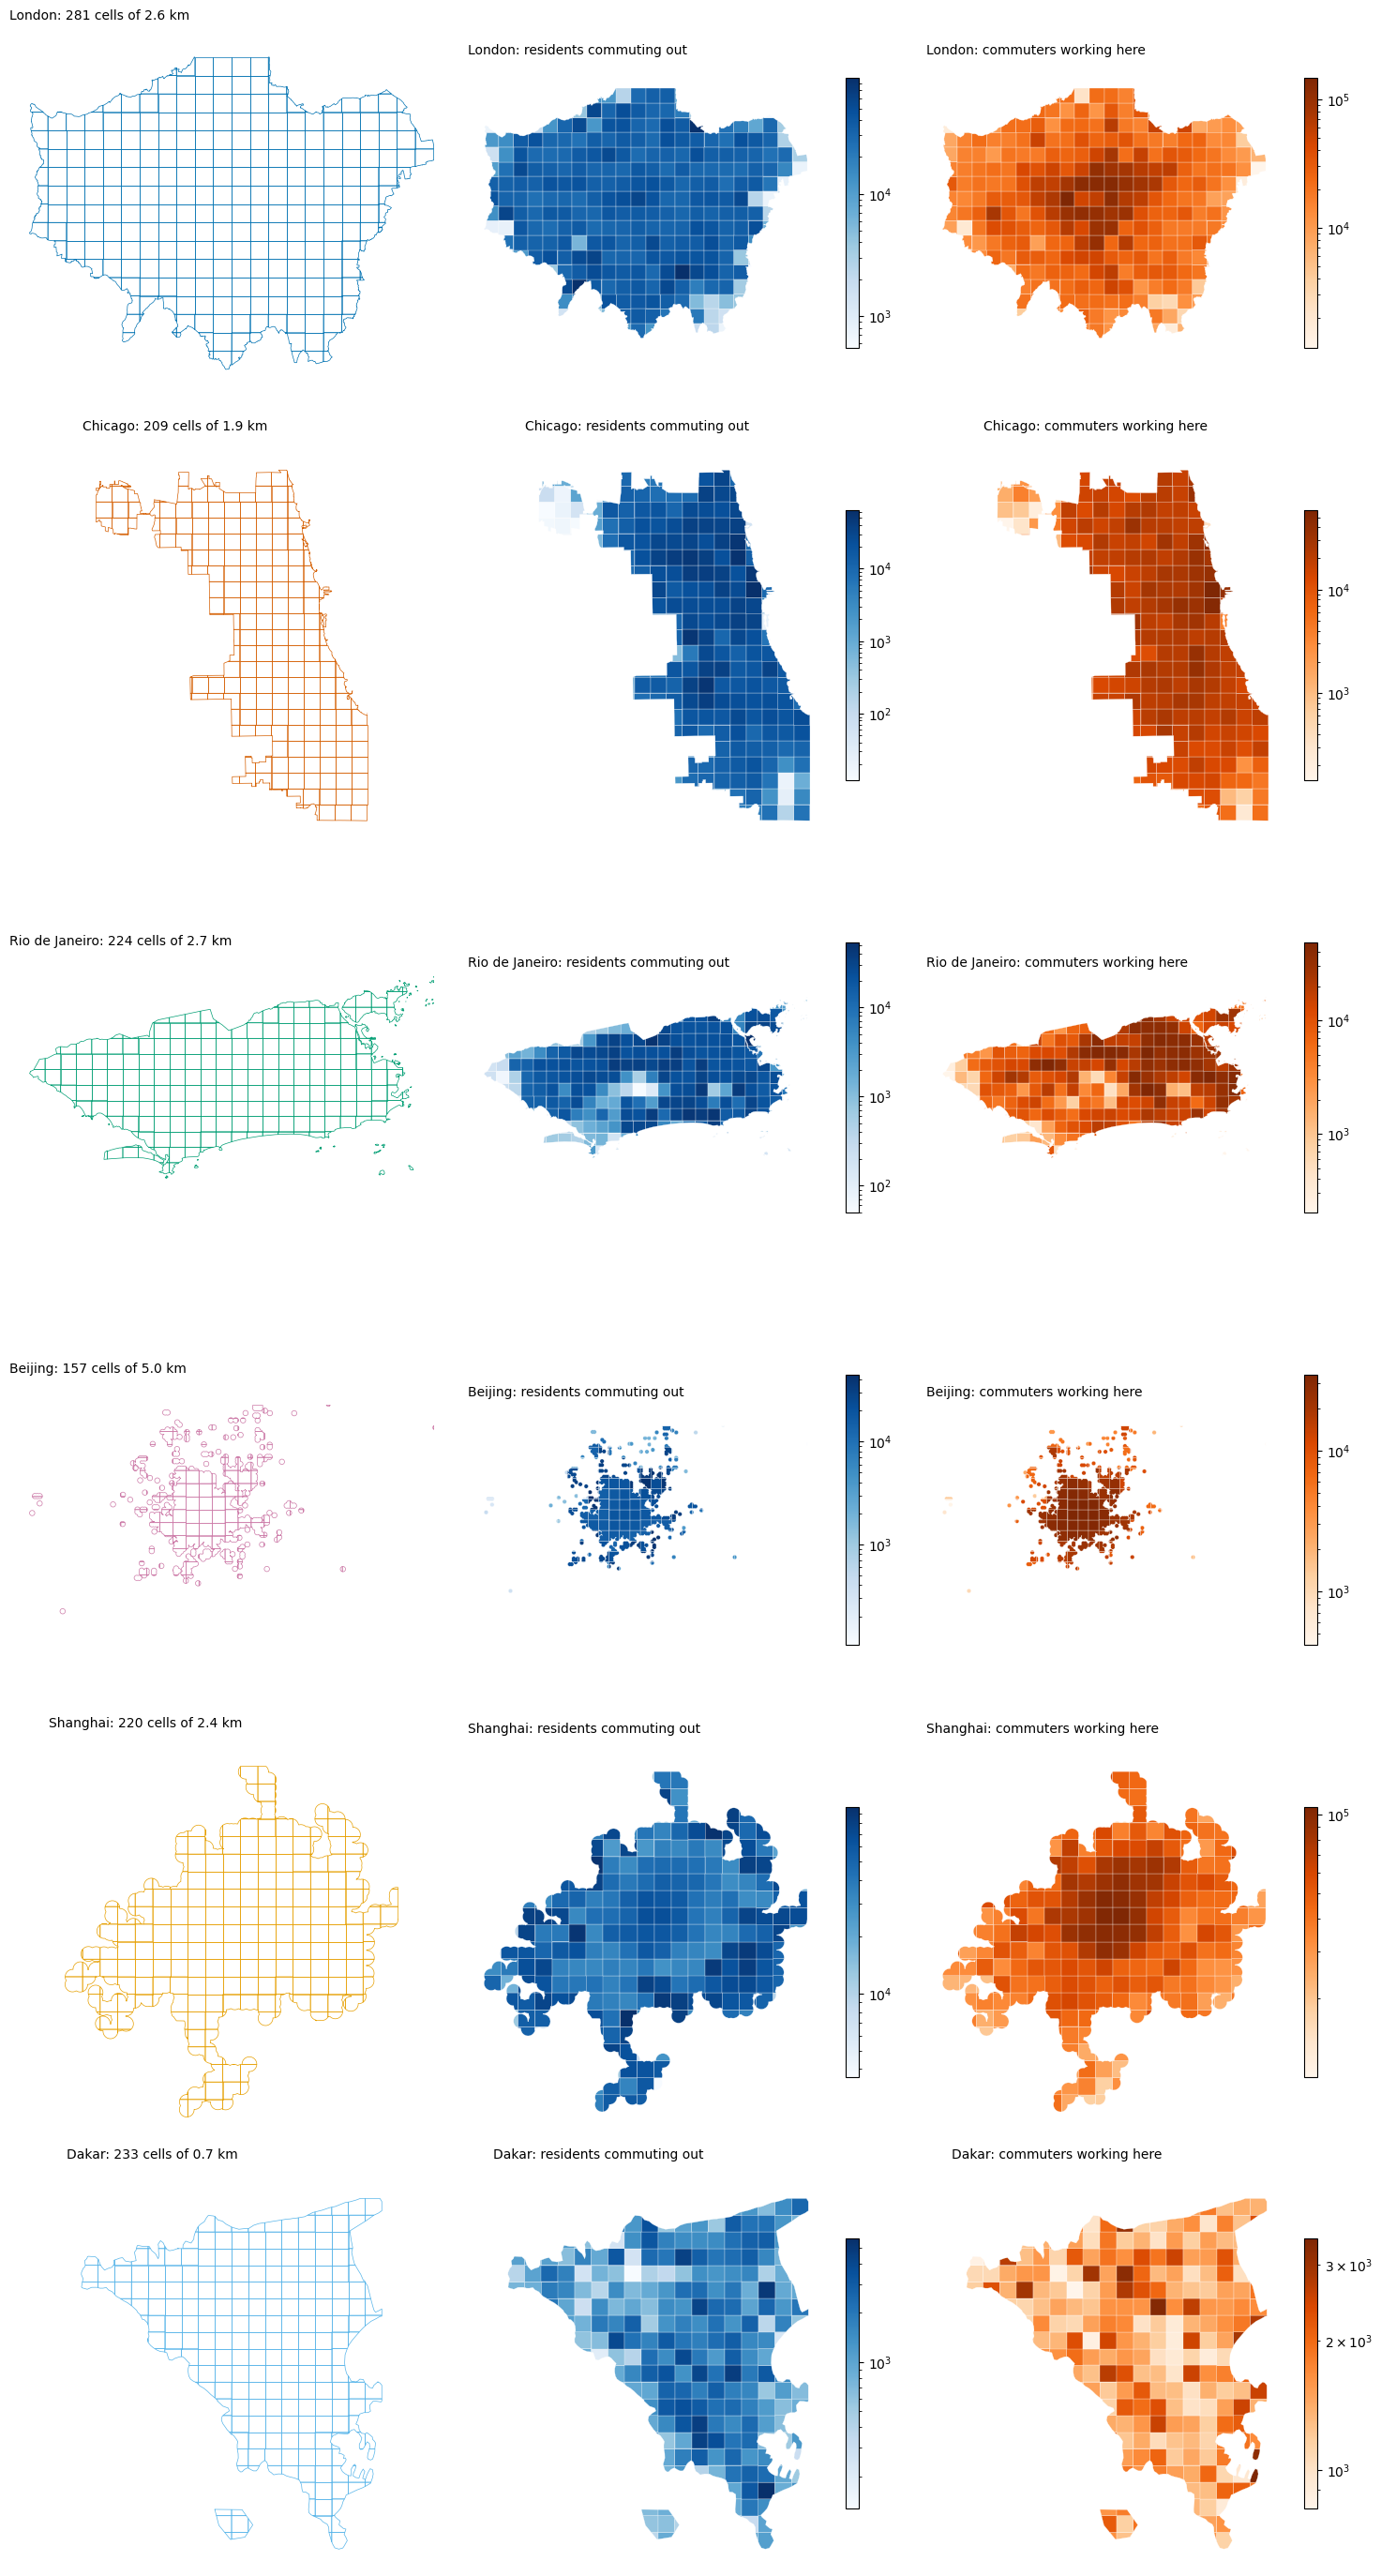

In [8]:
figure, axes = plt.subplots(nrows=len(CITIES), ncols=3, figsize=(15, 4.6 * len(CITIES)))

for row, (name, city) in zip(axes, cities.items()):
    regions = city["regions"]
    side_km = np.sqrt(regions["area_km2"].max())

    # Left: the grid.
    regions.plot(ax=row[0], facecolor="none", edgecolor=COLOURS[name], linewidth=0.5)
    row[0].set_title(f"{name}: {len(regions)} cells of {side_km:.1f} km", loc="left", fontsize=10)

    # Middle and right: residents and workers.
    for axis, column, cmap, title in [(row[1], "residents", "Blues", "residents commuting out"),
                                      (row[2], "workers", "Oranges", "commuters working here")]:
        values = regions[column]
        positive = values[values > 0]
        regions.assign(value=values.where(values > 0)).plot(
            column="value", ax=axis, cmap=cmap, norm=LogNorm(vmin=max(positive.min(), 1), vmax=positive.max()),
            edgecolor="white", linewidth=0.2, missing_kwds={"color": "#ececea"},
            legend=True, legend_kwds={"shrink": 0.7})
        axis.set_title(f"{name}: {title}", loc="left", fontsize=10)

    for axis in row:
        axis.set_axis_off()

figure.tight_layout()

### A zoomable map of one city

The same grid on a street basemap (Esri World Street Map), to see what the city polygon includes
and what it leaves out. Hover over a cell to read its id, residents and workers;
the fill colour follows the number of workers (darker means more). The map is
saved as `figures/04.1-grid-<city>.html` and can be opened in a browser.

In [9]:
regions = cities[EXAMPLE]["regions"]

# Leaflet works in latitude and longitude, so the grid is reprojected first.
grid = regions[["locations", "residents", "workers", "area_km2", "geometry"]].to_crs("EPSG:4326")
grid["residents"] = grid["residents"].round(0)
grid["workers"] = grid["workers"].round(0)
grid["area_km2"] = grid["area_km2"].round(2)

centre = [grid.geometry.union_all().centroid.y, grid.geometry.union_all().centroid.x]
# Esri street tiles: free to use without a key and served to embedded viewers such as the
# VS Code notebook pane (openstreetmap.org blocks those, CARTO now asks for an API key).
zoomable = folium.Map(location=centre, zoom_start=10, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles: Esri, HERE, Garmin, OpenStreetMap contributors", name="Esri World Street Map",
).add_to(zoomable)

folium.Choropleth(
    geo_data=grid.to_json(), data=grid, columns=["locations", "workers"], key_on="feature.properties.locations",
    fill_color="YlOrRd", fill_opacity=0.45, line_opacity=0.6, line_weight=1,
    legend_name="commuters working in the cell",
).add_to(zoomable)

folium.GeoJson(
    grid, style_function=lambda feature: {"fillOpacity": 0, "color": "#444444", "weight": 0.5},
    tooltip=folium.GeoJsonTooltip(fields=["locations", "residents", "workers", "area_km2"],
                                  aliases=["cell (column-row)", "residents commuting out", "commuters working here", "area km2"]),
).add_to(zoomable)

zoomable.save(FIGURES / f"04.1-grid-{EXAMPLE.lower().replace(' ', '-')}.html")
zoomable

## 5. The strongest pairs of one city

The ten pairs of cells with most commuters, with the grid position of both cells
(`locations` is column-row, counted from the south-west corner). The flow table
built above is used, so the same step works for any city by changing `EXAMPLE`.

In [10]:
regions = cities[EXAMPLE]["regions"]
od = cities[EXAMPLE]["od"]

strongest = od.nlargest(10, "flow").copy()
strongest["home_cell"] = regions["locations"].to_numpy()[strongest["origin"]]
strongest["work_cell"] = regions["locations"].to_numpy()[strongest["destination"]]
strongest["share_of_all_commuters_%"] = 100 * strongest["flow"] / od["flow"].sum()
strongest[["home_cell", "work_cell", "flow", "distance_km", "share_of_all_commuters_%"]].round(2)

,home_cell,work_cell,flow,distance_km,share_of_all_commuters_%
55564,14-14,11-10,3320.0,12.31,0.04
16997,6-3,8-9,2918.0,16.11,0.03
2546,1-8,8-9,2727.0,18.27,0.03
55580,14-14,12-10,2687.0,10.95,0.03
17028,6-3,10-6,2626.0,13.01,0.03
55547,14-14,10-10,2616.0,14.02,0.03
55548,14-14,10-11,2473.0,12.35,0.03
17013,6-3,9-8,2460.0,14.95,0.03
48249,13-4,12-8,2420.0,10.65,0.03
48234,13-4,11-9,2340.0,13.92,0.03


How many commuters a cell attracts versus how many live in it. Values far above 1
mark employment centres; this is the ratio the later time and cost analysis will
lean on, because it decides how far the average commuter must travel.

In [11]:
balance = (regions["workers"] / regions["residents"].replace(0, np.nan)).rename("workers_per_resident")
centres_table = regions.join(balance).sort_values("workers_per_resident", ascending=False)
centres_table[["locations", "residents", "workers", "workers_per_resident"]].head(8).round(2)

,locations,residents,workers,workers_per_resident
271,19-15,555.0,16945.0,30.53
265,19-9,726.0,8838.0,12.17
0,0-7,831.0,9266.0,11.15
177,13-1,602.0,6114.0,10.16
224,16-0,719.0,6465.0,8.99
223,15-14,2031.0,13393.0,6.59
77,6-15,3984.0,23571.0,5.92
78,7-1,3500.0,19428.0,5.55


## 6. Trip lengths

For each city, the distribution of commuting distance, each pair weighted by its
commuters. Distances are straight lines between cell centres, so they are shorter
than real routes, and trips inside a cell (which the data does not have) are
missing: the curves start at roughly one cell side. The vertical lines mark the
weighted median.

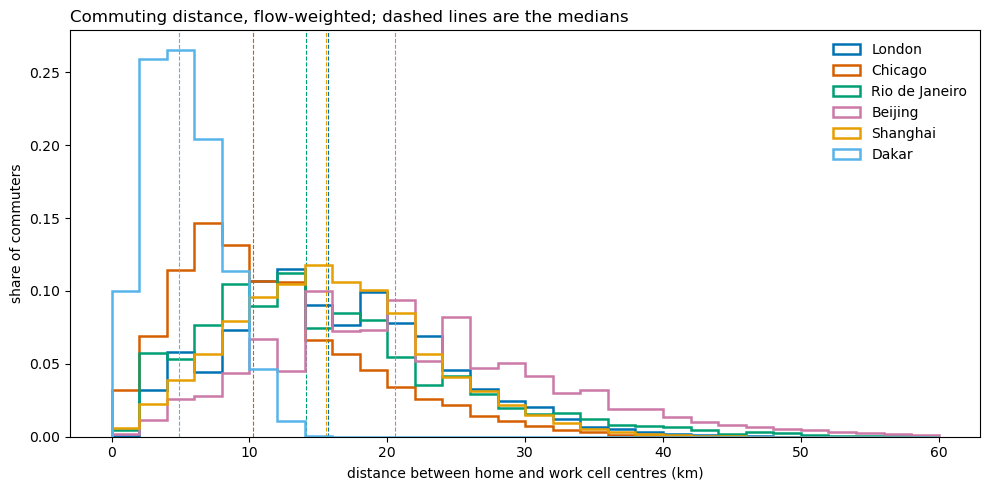

In [12]:
figure, axis = plt.subplots(figsize=(10, 5))
bins = np.arange(0, 62, 2)

for name, city in cities.items():
    od = city["od"]
    axis.hist(od["distance_km"], bins=bins, weights=od["flow"] / od["flow"].sum(),
              histtype="step", linewidth=1.8, color=COLOURS[name], label=name)
    axis.axvline(summary.loc[name, "median_distance_km"], color=COLOURS[name], linewidth=0.8, linestyle="--")

axis.set_xlabel("distance between home and work cell centres (km)")
axis.set_ylabel("share of commuters")
axis.set_title("Commuting distance, flow-weighted; dashed lines are the medians", loc="left")
axis.legend(frameon=False)
figure.tight_layout()

In [13]:
# The same information as numbers: the distance below which 25, 50, 75 and 90 % of the
# commuters stay, and the share of commuters under 5 km and over 20 km.
rows = []
for name, city in cities.items():
    od = city["od"]
    distance = od["distance_km"].to_numpy()
    flow = od["flow"].to_numpy()
    # Sort the pairs by distance and accumulate the commuters.
    order = np.argsort(distance)
    cumulative = np.cumsum(flow[order]) / flow.sum()
    row = {"city": name}
    for p in [25, 50, 75, 90]:
        # First position where the cumulative share reaches p percent.
        position = np.searchsorted(cumulative, p / 100)
        row[f"p{p}_km"] = distance[order][position]
    row["share_under_5_km"] = flow[distance < 5].sum() / flow.sum()
    row["share_over_20_km"] = flow[distance > 20].sum() / flow.sum()
    rows.append(row)
pd.DataFrame(rows).set_index("city").round(2)

,p25_km,p50_km,p75_km,p90_km,share_under_5_km,share_over_20_km
city,,,,,,
London,10.65,15.72,20.83,26.60,0.04,0.30
Chicago,6.19,10.24,15.39,21.35,0.15,0.12
Rio de Janeiro,8.62,14.12,20.66,28.32,0.07,0.26
Beijing,14.57,20.56,28.25,36.12,0.03,0.53
Shanghai,11.35,15.58,20.41,25.49,0.05,0.27
Dakar,3.31,4.91,7.09,9.05,0.51,0.00


## What we have and what comes next

- Six cities with real-data validation in the paper, read with one function each
  for the grid and the matrix, and summarised in one table.
- The grid cells are coarse and differ between cities (0.7 km in Dakar, 5 km in Beijing), so trip lengths
  are only comparable after accounting for the cell size, and anything shorter
  than a cell is invisible.
- Totals are inflated and not comparable to census counts; shares and averages
  per commuter are the safe quantities.

To repeat the Helsinki time, money and emissions analysis for these commutes, the
next notebooks need, per city: a street or transit network (or at least speeds
by mode), a mode split for commuting, fares and car costs, and emission factors.
Those inputs are city specific and will be collected one notebook at a time.